# Experiments

In [1]:
from utils import generate_random_normal, generate_plot

## Marchenko Pastur

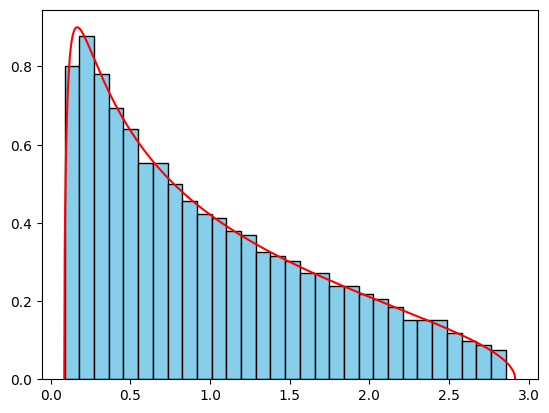

---


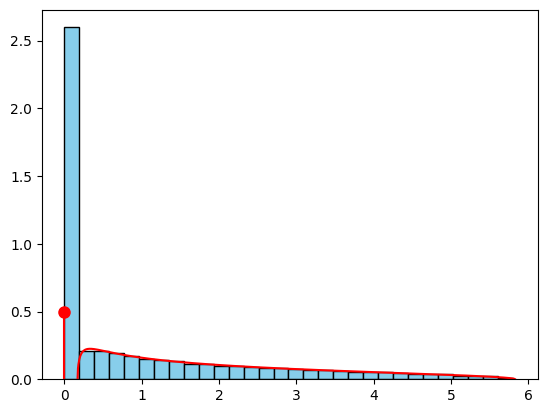

In [2]:
matrix1 = generate_random_normal(1000, 2000)
matrix2 = generate_random_normal(2000, 1000)

generate_plot(matrix1)
print("---")
generate_plot(matrix2)

## Neural Network

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [5]:
X_train = torch.randn(1000, 20)
y_train = torch.randint(0, 2, (1000, 1)).float()

X_test = torch.randn(200, 20)
y_test = torch.randint(0, 2, (200, 1)).float()

train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [6]:
model = nn.Sequential(
    nn.Linear(20, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1),
    nn.Sigmoid()
).to(device)

criterion = nn.BCELoss() 
optimizer = optim.Adam(model.parameters(), lr=0.005)

In [7]:
from utils import train_model, test_model

print("Starting Training...")
train_model(model, train_loader, criterion, optimizer, device, epochs=10)
    
print("\nStarting Testing...")
test_model(model, test_loader, criterion, device)

Starting Training...
Epoch 1/10 - Loss: 0.6961
Epoch 2/10 - Loss: 0.6809
Epoch 3/10 - Loss: 0.6640
Epoch 4/10 - Loss: 0.6425
Epoch 5/10 - Loss: 0.6197
Epoch 6/10 - Loss: 0.5812
Epoch 7/10 - Loss: 0.5585
Epoch 8/10 - Loss: 0.5183
Epoch 9/10 - Loss: 0.4893
Epoch 10/10 - Loss: 0.4375

Starting Testing...

Test Results - Loss: 1.0032, Accuracy: 50.00%
